# 05: Customer segments and campaign recommendations
**Goal:** turn our customer data into groups of customers, and say what the business should do with each group.

Notebook 04 told us who is probably leaving (churn risk) and what each customer is predicted to spend. Notebook 03 told us what each customer has actually spent so far. Here we combine churn risk and past spend into five segments, size each one, and attach a recommended campaign.

Make sure to run notebooks 03 and 04 first, as they create the files this notebook reads.

## Step 1: Load the customer data
We load two files, one row per customer in each:
- `customer_scores.csv` from notebook 04: churn risk and predicted LTV.
- `gold_customers.csv` from notebook 03: from this one we take `monetary` (each customer's **total past spend**) and `tenure_days` (days since their first purchase).

Careful with two similar names: `monetary_value` (from notebook 04) is the customer's *average order value*, and `monetary` (from notebook 03) is their *total spend*. Recall that `churn_risk` is only relevant for repeat buyers. One-time buyers always show 0, so we treat them as their own group.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
scores = pd.read_csv(PROJECT_ROOT / "data" / "exports" / "customer_scores.csv")
gold = pd.read_csv(PROJECT_ROOT / "data" / "exports" / "gold_customers.csv")

# add each customer's total past spend and tenure from notebook 03
scores = scores.merge(gold[["Customer_ID", "monetary", "tenure_days"]], on="Customer_ID")

repeat_buyers = scores[scores["repeat_buyer"]]
one_time_buyers = scores[~scores["repeat_buyer"]]

print(f"{len(scores):,} total customers")
print(f"{len(repeat_buyers):,} repeat buyers ({len(repeat_buyers)/len(scores):.0%})")
print(f"{len(one_time_buyers):,} one-time buyers ({len(one_time_buyers)/len(scores):.0%})")
scores.head().style.format({
    "frequency": "{:.0f}",
    "recency": "{:.0f}",
    "T": "{:.0f}",
    "monetary_value": "${:,.0f}",
    "monetary": "${:,.0f}",
    "tenure_days": "{:,}",
    "p_alive": "{:.1%}",
    "pred_purchases_12m": "{:.2f}",
    "pred_order_value": "${:,.0f}",
    "ltv_12m": "${:,.0f}",
    "churn_risk": "{:.1%}",
})

5,878 total customers
4,189 repeat buyers (71%)
1,689 one-time buyers (29%)


,Customer_ID,repeat_buyer,frequency,recency,T,monetary_value,p_alive,pred_purchases_12m,pred_order_value,ltv_12m,ltv_decile,churn_risk,monetary,tenure_days
0,12346,True,7,400,725,$997,62.6%,2.19,$999,"$2,186",9,37.4%,"$77,556",726
1,12347,True,7,402,404,$717,99.0%,5.79,$720,"$4,166",10,1.0%,"$5,633",405
2,12348,True,4,363,438,$449,96.4%,3.20,$453,"$1,451",8,3.6%,"$2,019",439
3,12349,True,3,571,589,$997,97.5%,1.96,"$1,003","$1,970",9,2.5%,"$4,429",590
4,12350,False,0,0,310,$0,100.0%,0.63,$362,$227,3,0.0%,$334,311


## Step 2: Choose the cut-offs
We split repeat buyers on two questions:
- **Is the customer high value?** Total past spend (`monetary`) at or above the repeat-buyer median.
- **Is the customer at risk?** Churn risk at or above **0.25**. We use 0.25, not 0.5, because most repeat buyers have a very low churn risk (the middle customer is about 0.04). A 0.5 cut-off would flag only about 7% of them and miss people who are slipping away.

**Why past spend and not predicted LTV?** Predicted LTV and churn risk both come from the same BG/NBD estimate of whether a customer is still active. A customer the model thinks has left gets a high churn risk *and* a near-zero predicted LTV, so using both would count the same signal twice and label every likely-lost customer "low value", even ones who spent tens of thousands. Past spend doesn't depend on that estimate. It tells us how valuable the customer *has been*, and churn risk tells us whether we are about to lose them.

Note that both cut-offs are arbitrary; we can change them below and the following cells will update if we rerun them.

In [2]:
RISK_CUTOFF = 0.25

repeat = scores[scores["repeat_buyer"]]
VALUE_CUTOFF = repeat["monetary"].median()

print(f"High value = past spend of ${VALUE_CUTOFF:,.0f} or more")
print(f"At risk    = churn risk of {RISK_CUTOFF} or more "
      f"({(repeat['churn_risk'] >= RISK_CUTOFF).mean():.0%} of repeat buyers)")

High value = past spend of $1,420 or more
At risk    = churn risk of 0.25 or more (17% of repeat buyers)


## Step 3: Assign each customer to a segment
Five segments:

| Segment | Who they are |
|---|---|
| **Champions** | High past spend, low risk |
| **At-risk high value** | High past spend, high risk. Big past spenders who are slipping away. |
| **Loyal low-value** | Lower past spend, low risk |
| **Fading low-value** | Lower past spend, high risk |
| **One-time buyers** | Bought once. The model can't judge them yet. |

In [3]:
def assign_segment(row):
    if not row["repeat_buyer"]:
        return "One-time buyers"
    high_value = row["monetary"] >= VALUE_CUTOFF
    at_risk = row["churn_risk"] >= RISK_CUTOFF
    if high_value and not at_risk:
        return "Champions"
    if high_value and at_risk:
        return "At-risk high value"
    if not high_value and not at_risk:
        return "Loyal low-value"
    return "Fading low-value"

scores["segment"] = scores.apply(assign_segment, axis=1)
scores["segment"].value_counts()

segment
Champions             1912
One-time buyers       1689
Loyal low-value       1582
Fading low-value       512
At-risk high value     183
Name: count, dtype: int64

### Check: who landed in At-risk high value?
These are the ten biggest past spenders in the segment. Notice that their predicted LTV is tiny, because the model thinks they have already left. If we had ranked value by predicted LTV, they would have been labeled "low value" and missed.

In [4]:
at_risk = scores[scores["segment"] == "At-risk high value"]
print(f"{len(at_risk):,} customers are at risk but have a high past spend (total past spend ${at_risk['monetary'].sum():,.0f}, total predicted LTV ${at_risk['ltv_12m'].sum():,.0f})")

at_risk.sort_values("monetary", ascending=False).head(10)[["Customer_ID", "monetary", "ltv_12m", "churn_risk"]].style.format({
    "monetary": "${:,.0f}",
    "ltv_12m": "${:,.2f}",
    "churn_risk": "{:.1%}",
}).hide(axis="index")

183 customers are at risk but have a high past spend (total past spend $932,731, total predicted LTV $108,011)


Customer_ID,monetary,ltv_12m,churn_risk
12346,"$77,556","$2,185.52",37.4%
16754,"$67,502",$1.91,100.0%
17850,"$56,600",$2.00,100.0%
13093,"$54,944",$0.16,100.0%
13902,"$34,095",$61.02,97.1%
12482,"$23,691",$19.44,99.3%
14063,"$22,710",$602.75,82.6%
15808,"$18,410",$106.00,98.7%
13564,"$17,250","$5,366.85",32.2%
15768,"$15,601","$5,086.12",26.7%


## Step 4: Size each segment
For every segment: how many customers, their average past spend, their average predicted LTV, and what share of all predicted 12-month revenue they hold. This shows where the money is.

In [5]:
order = ["Champions", "At-risk high value", "Loyal low-value", "Fading low-value", "One-time buyers"]

summary = scores.groupby("segment").agg(
    customers=("Customer_ID", "count"),
    avg_past_spend=("monetary", "mean"),
    avg_ltv=("ltv_12m", "mean"),
    total_ltv=("ltv_12m", "sum"),
).reindex(order)
summary["share_of_customers"] = summary["customers"] / summary["customers"].sum()
summary["share_of_revenue"] = summary["total_ltv"] / summary["total_ltv"].sum()

summary.style.format({
    "customers": "{:,}",
    "avg_past_spend": "${:,.0f}",
    "avg_ltv": "${:,.0f}",
    "total_ltv": "${:,.0f}",
    "share_of_customers": "{:.1%}",
    "share_of_revenue": "{:.1%}",
})

,customers,avg_past_spend,avg_ltv,total_ltv,share_of_customers,share_of_revenue
segment,,,,,,
Champions,"1,912","$7,615","$3,090","$5,908,841",32.5%,77.5%
At-risk high value,183,"$5,097",$590,"$108,011",3.1%,1.4%
Loyal low-value,"1,582",$767,$604,"$955,232",26.9%,12.5%
Fading low-value,512,$667,$181,"$92,810",8.7%,1.2%
One-time buyers,"1,689",$412,$329,"$556,270",28.7%,7.3%


## Step 5: Visualize the data
Two bars per segment: the share of customers vs the share of predicted revenue. We can see that a small share of customers holds most of the predicted revenue.

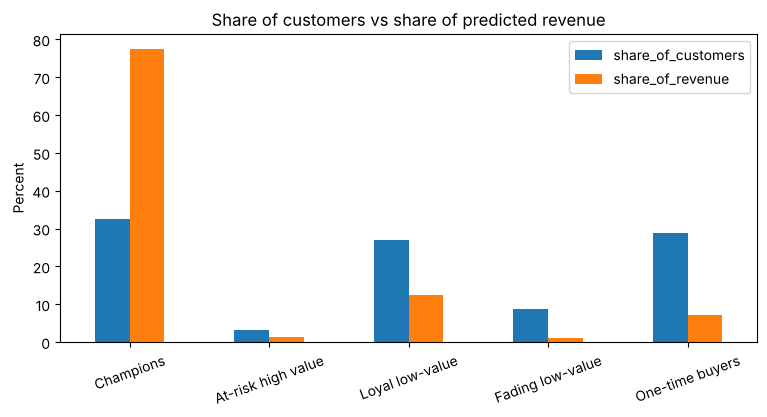

In [6]:
shares = summary[["share_of_customers", "share_of_revenue"]] * 100
shares.plot(kind="bar", figsize=(9, 4), title="Share of customers vs share of predicted revenue")
plt.ylabel("Percent")
plt.xlabel("")
plt.xticks(rotation=20)
plt.show()

## Step 6: Estimate what each campaign could be worth
Now the business question: if we run a campaign on each segment, how much revenue could it add?

**These rates are assumptions and would need further validation.** They are placeholders based on common marketing assumptions, and the real numbers should come from an A/B test (send the campaign to half the segment and compare).

For four segments: Extra revenue estimate = segment predicted revenue x assumed lift

**At-risk high value is sized differently.** Their predicted LTV is close to zero because the model thinks they are gone, so a percentage of it would be meaningless. Instead we ask how much of what they used to spend we could win back: **yearly past spend x an assumed win-back rate (10%)**. Yearly spend is their total past spend spread over their tenure, using at least 365 days so customers with under a year of history aren't overstated.

Because the two methods differ, we show the two parts of the total separately.

In [7]:
#ASSUMED lifts (we can edit these as needed). Share of the segment's predicted revenue the campaign adds.
lift = {
    "Champions": 0.05,            # loyalty perks keep them buying a little more
    "Loyal low-value": 0.10,      # cross-sell and bundles to raise order size
    "Fading low-value": 0.05,     # automated email, not much lift expected
    "One-time buyers": 0.15,      # second-purchase offer
}
WINBACK_RATE = 0.10               # ASSUMED share of an at-risk customer's yearly past spend that we win back

summary["assumed_lift"] = pd.Series(lift)       # At-risk high value has no lift; it is sized below
summary["extra_revenue"] = summary["total_ltv"] * summary["assumed_lift"]

# At-risk high value: sized on past spend instead of predicted LTV
annual_spend = at_risk["monetary"] / at_risk["tenure_days"].clip(lower=365) * 365
summary.loc["At-risk high value", "extra_revenue"] = annual_spend.sum() * WINBACK_RATE

four_segments = summary["extra_revenue"].drop("At-risk high value").sum()
win_back = summary.loc["At-risk high value", "extra_revenue"]
print(f"Four segments (predicted revenue x lift):        ${four_segments:,.0f}")
print(f"At-risk high value (past spend x win-back rate): ${win_back:,.0f}")
print(f"Total extra 12-month revenue if every assumption holds: ${four_segments + win_back:,.0f}")
summary[["customers", "total_ltv", "assumed_lift", "extra_revenue"]].style.format({
    "customers": "{:,}",
    "total_ltv": "${:,.0f}",
    "assumed_lift": "{:.0%}",
    "extra_revenue": "${:,.0f}",
}, na_rep="see note")

Four segments (predicted revenue x lift):        $479,046
At-risk high value (past spend x win-back rate): $52,303
Total extra 12-month revenue if every assumption holds: $531,349


,customers,total_ltv,assumed_lift,extra_revenue
segment,,,,
Champions,"1,912","$5,908,841",5%,"$295,442"
At-risk high value,183,"$108,011",see note,"$52,303"
Loyal low-value,"1,582","$955,232",10%,"$95,523"
Fading low-value,512,"$92,810",5%,"$4,641"
One-time buyers,"1,689","$556,270",15%,"$83,440"


## Step 7: Recommendations
One action per segment, with the size of the prize from Step 6 and a note on how heavily to spend. The rule of thumb: spend the most where the customers are worth the most, and keep the cheap, automated tactics for low-value groups.

In [8]:
actions = pd.DataFrame({
    "segment": order,
    "recommended_campaign": [
        "Loyalty perks and early access to new products. Do not discount as they already buy.",
        "Win-back: account-manager calls to the largest past spenders, and a targeted win-back email for the rest.",
        "Cross-sell and bundles to raise order size. Standard email send.",
        "Automated reactivation email only. Do not spend on discounts here.",
        "Second-purchase offer within weeks of the first order, while their order is still fresh on their mind.",
    ],
    "spend_level": ["Medium", "High", "Low", "Very low", "Medium"],
})
recs = actions.merge(
    summary[["customers", "extra_revenue"]].round(0).reset_index(), on="segment")
recs = recs.sort_values("extra_revenue", ascending=False)
(recs.style
    .format({"customers": "{:,}", "extra_revenue": "${:,.0f}"})
    .hide(axis="index")
    .set_properties(subset=["recommended_campaign"],
                    **{"white-space": "normal", "text-align": "left", "min-width": "350px"})
    .set_properties(subset=["segment"], **{"font-weight": "bold", "text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
)

segment,recommended_campaign,spend_level,customers,extra_revenue
Champions,Loyalty perks and early access to new products. Do not discount as they already buy.,Medium,"1,912","$295,442"
Loyal low-value,Cross-sell and bundles to raise order size. Standard email send.,Low,"1,582","$95,523"
One-time buyers,"Second-purchase offer within weeks of the first order, while their order is still fresh on their mind.",Medium,"1,689","$83,440"
At-risk high value,"Win-back: account-manager calls to the largest past spenders, and a targeted win-back email for the rest.",High,183,"$52,303"
Fading low-value,Automated reactivation email only. Do not spend on discounts here.,Very low,512,"$4,641"


## Step 8: Save the results
We save the customer list with its segment (so a campaign team could use it) and the recommendations table.

In [9]:
EXPORT_DIR = PROJECT_ROOT / "data" / "exports"
scores.to_csv(EXPORT_DIR / "customer_segments.csv", index=False)
recs.to_csv(EXPORT_DIR / "segment_recommendations.csv", index=False)
print("Saved customer_segments.csv and segment_recommendations.csv to data/exports/")

Saved customer_segments.csv and segment_recommendations.csv to data/exports/


## What we found, and what to be careful about
*These numbers come from the run with the cut-offs in Step 2. If you change the cut-offs or assumptions, rerun the notebook and update this section.*

- **Champions:** 1,912 customers (33% of customers) hold about 78% of predicted 12-month revenue and have averaged $7,615 in past spend each. Protect them with loyalty perks, not discounts.
- **At-risk high value:** 183 customers who have spent $932,731 in total and are now likely slipping away. The model gives them a predicted LTV of only $108,011 because it thinks they have left, which is why past spend is the right way to spot them. The biggest few have spent $34,000 to $78,000 each, so they are the best win-back targets.
- **One-time buyers:** 1,689 customers (29%). Notebook 04 showed 74% of one-time buyers did not return in the test window, so a second-purchase campaign is the biggest retention lever by volume.
- **Fading low-value:** 512 customers who spent little and are likely gone. Not worth a discount; an automated email is enough.
- **A correction along the way:** an earlier version ranked value by predicted LTV, which counted churn risk twice and left only 32 customers in At-risk high value. Ranking by past spend raised that to 183.

**Limits:**
- The lift rates and the win-back rate in Step 6 are assumptions. A real result needs A/B tests.
- Past spend favors long-time customers and says nothing about recent activity. Churn risk covers that part.
- The win-back estimate assumes we can recover some of what these customers used to spend. Some, with churn risk near 100%, may be gone for good.
- Order values are capped for the biggest wholesale buyers (notebook 04), so Champions' predicted revenue is understated.
- The risk and past-spend cut-offs are arbitrary. Different values would move customers between segments.
- Segments come from a forecast, not certainty; some customers will land in the wrong group.
- All amounts are shown with $ for readability; the source data is in British pounds.
